[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zyclasses/AILab/blob/main/Week5_Training_Deep_Networks_solution.ipynb)

# SOLUTION — Week 5 Lab: Training Deep Networks

This lab goes with Lectures 8 and 9. It is **practice**: nothing to hand in, and it is good preparation for the midterm.
It takes about an hour.

| Exercise | Topic | Lecture | Time |
|---|---|---|---|
| 1 | A deep network that won't train, and He init | 8 | 12 min |
| 2 | Batch norm by hand, then in a deep network | 8 | 12 min |
| 3 | Momentum on a narrow valley | 9 | 10 min |
| 4 | Adam and AdamW, written by hand | 9 | 12 min |
| 5 | Dropout, a schedule, and train vs eval mode | 9 | 15 min |

**How to use it:** replace every `[YOUR CODE]` with one line of code. Where a step says **predict first**, write your
guess down before you run the cell. Run the cells from top to bottom: later exercises reuse names from earlier ones.

The settings here are a little different from the slides (other depths, numbers and learning rates), so your results
will differ from the lecture's. Small differences from run to run, and from the numbers quoted below, are normal.

**First:** choose *Runtime → Change runtime type → T4 GPU*, then run the setup cell.

## Setup (run this first)

In [1]:
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)          # if this says cpu, switch the runtime to a T4 GPU

# Fashion MNIST: 55,000 training and 5,000 validation images, standardized, kept on the GPU
data = torchvision.datasets.FashionMNIST(root="data", train=True, download=True)
torch.manual_seed(42)
train_part, valid_part = torch.utils.data.random_split(range(60_000), [55_000, 5_000])
pixels = data.data.float().div(255).reshape(-1, 28 * 28)
X_train, y_train = pixels[train_part.indices].to(device), data.targets[train_part.indices].to(device)
X_valid, y_valid = pixels[valid_part.indices].to(device), data.targets[valid_part.indices].to(device)
means, stds = X_train.mean(dim=0), X_train.std(dim=0).clamp(min=0.01)
X_train, X_valid = (X_train - means) / stds, (X_valid - means) / stds
xentropy = nn.CrossEntropyLoss()

def batches(X, y, batch_size=128):
    """Shuffled mini-batches of tensors that are already on the GPU (a quick DataLoader)."""
    order = torch.randperm(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        rows = order[i:i + batch_size]
        yield X[rows], y[rows]

def valid_accuracy(model):
    """Accuracy (%) on the 5,000 validation images, in whatever mode the model is in."""
    with torch.no_grad():
        return round((model(X_valid).argmax(dim=1) == y_valid).float().mean().item() * 100, 1)

def fit(model, optimizer, n_epochs):
    """Lecture 7's training loop. Returns the validation accuracy after each epoch."""
    accuracies = []
    for epoch in range(n_epochs):
        model.train()
        for X_batch, y_batch in batches(X_train, y_train):
            loss = xentropy(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        model.eval()
        accuracies.append(valid_accuracy(model))
    return accuracies

print("training images:", tuple(X_train.shape), " validation images:", tuple(X_valid.shape))

device: cuda


training images: (55000, 784)  validation images: (5000, 784)


---
## Exercise 1: A deep network that won't train, and He init (Lecture 8)

The network below has **12 hidden layers of 128 units**, with ReLU. Lecture 8 used 20 layers of 100.

**Step 1.** Complete `grad_sizes`. It runs one batch backward and returns the length (the norm) of each hidden
layer's weight gradient, from the first layer to the last.

**Predict first:** with PyTorch's default init, which hidden layer gets the *smaller* gradient, the first or the last?

In [2]:
def deep_mlp(n_hidden=12, n_units=128):
    layers, n_in = [], 28 * 28
    for _ in range(n_hidden):
        layers += [nn.Linear(n_in, n_units), nn.ReLU()]
        n_in = n_units
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers).to(device)

def grad_sizes(model):
    X_batch, y_batch = X_valid[:256], y_valid[:256]
    model.zero_grad()
    loss = xentropy(model(X_batch), y_batch)
    loss.backward()  # compute the gradients
    hidden = [m for m in model if isinstance(m, nn.Linear)][:-1]   # every Linear but the output layer
    return [m.weight.grad.norm().item() for m in hidden]  # return [...]: the norm of each hidden layer's weight gradient

torch.manual_seed(0)
sizes = grad_sizes(deep_mlp())
print(f"default init: first hidden layer {sizes[0]:.1e}, last hidden layer {sizes[-1]:.1e}")

default init: first hidden layer 7.3e-05, last hidden layer 1.3e-02


**Step 2.** Write He init, apply it to a fresh network, and measure again. (`nn.init.kaiming_normal_` and
`nn.init.zeros_` change a tensor in place.)

In [3]:
def he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_normal_(module.weight, nonlinearity="relu")  # He init for the weights
        nn.init.zeros_(module.bias)  # the biases start at 0

torch.manual_seed(0)
he_model = deep_mlp().apply(he_init)  # he_model = ... (a fresh deep_mlp, with he_init applied)
sizes = grad_sizes(he_model)
print(f"He init:      first hidden layer {sizes[0]:.1e}, last hidden layer {sizes[-1]:.1e}")

He init:      first hidden layer 2.1e+00, last hidden layer 2.4e+00


**Step 3.** Train both for 3 epochs, same seed, same everything else.

**You're done when:** the default init stays near **10%** (guessing) and He init reaches about **87%**.

In [4]:
torch.manual_seed(0)
default_model = deep_mlp()
print("default init:", fit(default_model, torch.optim.SGD(default_model.parameters(), lr=0.01, momentum=0.9), 3))

torch.manual_seed(0)
he_model = deep_mlp().apply(he_init)
print("He init:     ", fit(he_model, torch.optim.SGD(he_model.parameters(), lr=0.01, momentum=0.9), 3))

default init: [10.2, 9.8, 10.5]


He init:      [83.5, 85.2, 86.9]


*Finished early?* Try `deep_mlp(n_hidden=3)` with the default init. Does depth matter?

---
## Exercise 2: Batch norm by hand, then in a deep network (Lecture 8)

**Step 1.** A batch of 4 rows and 2 features. Do batch norm's four steps yourself, with $\gamma = 2$ and $\beta = 0.5$.
Use the variance that divides by $m$ (`unbiased=False`), as batch norm does.

**Predict first:** after step 4, what are the mean and the standard deviation of each column of `z`?

In [5]:
X = torch.tensor([[2., 10.],
                  [4., 30.],
                  [6., 10.],
                  [8., 30.]])
gamma, beta, eps = 2.0, 0.5, 1e-5

mean = X.mean(dim=0)  # mean = ... (step 1: each feature's mean over the batch)
var = X.var(dim=0, unbiased=False)  # var = ... (step 2: each feature's variance)
x_hat = (X - mean) / torch.sqrt(var + eps)  # x_hat = ... (step 3: normalize)
z = gamma * x_hat + beta  # z = ... (step 4: scale and shift)
print(z)
print("column means:", z.mean(dim=0), " column stds:", z.std(dim=0, unbiased=False))

bn = nn.BatchNorm1d(2)          # PyTorch's batch norm, with the same gamma and beta
with torch.no_grad():
    bn.weight.fill_(gamma)
    bn.bias.fill_(beta)
    print("same as nn.BatchNorm1d:", torch.allclose(bn(X), z, atol=1e-4))

tensor([[-2.1833, -1.5000],
        [-0.3944,  2.5000],
        [ 1.3944, -1.5000],
        [ 3.1833,  2.5000]])
column means: tensor([0.5000, 0.5000])  column stds: tensor([2.0000, 2.0000])
same as nn.BatchNorm1d: True


**Step 2.** Put a `BatchNorm1d` after every hidden `Linear`, before the ReLU, and train the 12-layer network with
PyTorch's **default** init: the init that was stuck at 10% in Exercise 1.

**You're done when:** it trains to about **86%** in 3 epochs, without He init.

In [6]:
def deep_mlp_bn(n_hidden=12, n_units=128):
    layers, n_in = [], 28 * 28
    for _ in range(n_hidden):
        layers += [nn.Linear(n_in, n_units), nn.BatchNorm1d(n_units), nn.ReLU()]  # layers += [...]: Linear, then batch norm, then ReLU
        n_in = n_units
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers).to(device)

torch.manual_seed(0)
bn_model = deep_mlp_bn()            # default init: no he_init here
print("default init + batch norm:", fit(bn_model, torch.optim.SGD(bn_model.parameters(), lr=0.01, momentum=0.9), 3))

default init + batch norm: [84.4, 85.9, 85.7]


---
## Exercise 3: Momentum on a narrow valley (Lecture 9)

The loss is $f(x, y) = (x^2 + 50\,y^2)/2$, so the gradient is $(x,\ 50y)$. We start at $(-8, 1)$ and write the update
ourselves, without `torch.optim`.

**Step 1.** Complete the two lines of momentum: $v \leftarrow \beta v + g$, then $w \leftarrow w - \eta\, v$.

**Predict first:** with `beta=0`, what is `v` at every step? So what is the run with `beta=0`?

In [7]:
def run(beta, lr=0.03, n_steps=300):
    w = torch.tensor([-8.0, 1.0])            # (x, y)
    v = torch.zeros(2)                      # the velocity starts at 0
    path = [w.clone()]
    for _ in range(n_steps):
        g = torch.tensor([w[0], 50 * w[1]])  # the gradient of (x^2 + 50 y^2) / 2
        v = beta * v + g  # v = ... (the velocity)
        w = w - lr * v  # w = ... (the step)
        path.append(w.clone())
    return torch.stack(path)

def settle_step(path):
    """The step after which the path stays within 0.1 of the minimum (0, 0)."""
    far = (path.norm(dim=1) >= 0.1).nonzero()
    return far.max().item() + 1 if len(far) else 0

sgd_path, momentum_path = run(beta=0.0), run(beta=0.9)
print("plain SGD settles at step   ", settle_step(sgd_path))
print("momentum 0.9 settles at step", settle_step(momentum_path))

plain SGD settles at step    144
momentum 0.9 settles at step 80


**Step 2.** Plot the first 60 steps of both. Where does plain SGD spend its steps? What does momentum do near the
minimum?

**You're done when:** plain SGD needs about **144** steps and momentum about **80**, at the same learning rate.

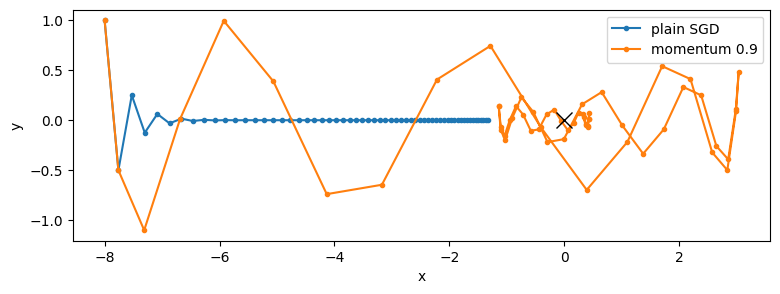

In [8]:
plt.figure(figsize=(9, 3))
plt.plot(sgd_path[:60, 0], sgd_path[:60, 1], ".-", label="plain SGD")
plt.plot(momentum_path[:60, 0], momentum_path[:60, 1], ".-", label="momentum 0.9")
plt.plot(0, 0, "kx", markersize=12)
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

*Finished early?* Try `lr=0.045` for both. The steep direction's limit for plain SGD is $\eta < 2/50 = 0.04$.

---
## Exercise 4: Adam and AdamW, written by hand (Lecture 9)

Lecture 9's update rules, as code. With `decoupled=False` the weight decay is added to the gradient (`Adam`'s
`weight_decay`). With `decoupled=True` it shrinks `w` directly (`AdamW`). Everything else is the same.

**Step 1.** Complete the four lines: the two kinds of weight decay, and the two bias corrections (the "hats").

In [9]:
def adam_steps(grads, decoupled, lr=0.02, wd=0.05):
    b1, b2, eps = 0.9, 0.999, 1e-8
    w, m, s = torch.ones(2), torch.zeros(2), torch.zeros(2)
    for t, g in enumerate(grads, start=1):
        if decoupled:
            w = w * (1 - lr * wd)  # w = ... (AdamW: shrink w directly)
        else:
            g = g + wd * w  # g = ... (Adam's weight_decay: add the pull to the gradient)
        m = b1 * m + (1 - b1) * g
        s = b2 * s + (1 - b2) * g ** 2
        m_hat = m / (1 - b1 ** t)  # m_hat = ... (bias correction for m)
        s_hat = s / (1 - b2 ** t)  # s_hat = ... (bias correction for s)
        w = w - lr * m_hat / (s_hat.sqrt() + eps)
    return w

# two weights, both starting at 1: A gets no gradient, B gets +5, -5, +5, ...
grads = [torch.tensor([0.0, 5.0 * (-1) ** t]) for t in range(150)]

**Predict first:** with `decoupled=False`, which weight ends closer to 0, A or B? With `decoupled=True`?

**Step 2.** Run both, and check your code against PyTorch's own `Adam` and `AdamW`.

**You're done when:** both lines print `True`. With `Adam`'s `weight_decay`, A ends near **0.0002** and B near
**0.94**. With `AdamW`, both end near **0.83 to 0.86**.

In [10]:
for decoupled, Optimizer in [(False, torch.optim.Adam), (True, torch.optim.AdamW)]:
    w = torch.ones(2, requires_grad=True)
    optimizer = Optimizer([w], lr=0.02, weight_decay=0.05)
    for g in grads:
        w.grad = g.clone()
        optimizer.step()
    mine = adam_steps(grads, decoupled)
    print(f"{Optimizer.__name__:6s} A, B = {mine.tolist()}   matches PyTorch: {torch.allclose(mine, w.detach(), atol=1e-5)}")

Adam   A, B = [0.0002449815219733864, 0.9364727735519409]   matches PyTorch: True
AdamW  A, B = [0.8606448173522949, 0.8303082585334778]   matches PyTorch: True


**Step 3.** Where does A's `AdamW` value come from? A gets no gradient, so only the decay acts on it. Compute it in
one line from `lr`, `wd` and the number of steps.

In [11]:
print((1 - 0.02 * 0.05) ** 150)  # print(...): (1 - lr * wd) to the power of the number of steps

0.8606433826830363


---
## Exercise 5: Dropout, a schedule, and train vs eval mode (Lecture 9)

A network with **2 hidden layers of 256 units** and **dropout 0.3**, trained on only **5,000** images with `AdamW` and a
cosine schedule over 15 epochs.

**Step 1.** Complete the network, the optimizer and the scheduler, and put `scheduler.step()` where it belongs.

In [12]:
torch.manual_seed(1)
small = torch.randperm(len(X_train), device=device)[:5000]
X_small, y_small = X_train[small], y_train[small]

def small_net(p):
    return nn.Sequential(
        nn.Linear(28 * 28, 256), nn.ReLU(), nn.Dropout(p),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(p),  # the second hidden layer: Linear, ReLU, Dropout
        nn.Linear(256, 10),
    ).to(device).apply(he_init)

torch.manual_seed(0)
model = small_net(p=0.3)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)  # optimizer = ... (AdamW, lr 0.001, weight decay 0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)  # scheduler = ... (cosine over 15 epochs)

for epoch in range(15):
    model.train()
    for X_batch, y_batch in batches(X_small, y_small):
        loss = xentropy(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    scheduler.step()  # step the scheduler: once per epoch, after the batches
    model.eval()
    print(f"epoch {epoch + 1:2d}: learning rate {scheduler.get_last_lr()[0]:.6f}, valid accuracy {valid_accuracy(model)}%")

epoch  1: learning rate 0.000989, valid accuracy 78.6%


epoch  2: learning rate 0.000957, valid accuracy 79.5%
epoch  3: learning rate 0.000905, valid accuracy 81.8%
epoch  4: learning rate 0.000835, valid accuracy 82.5%
epoch  5: learning rate 0.000750, valid accuracy 84.2%


epoch  6: learning rate 0.000655, valid accuracy 84.1%


epoch  7: learning rate 0.000552, valid accuracy 84.5%
epoch  8: learning rate 0.000448, valid accuracy 84.3%
epoch  9: learning rate 0.000345, valid accuracy 84.1%
epoch 10: learning rate 0.000250, valid accuracy 84.1%


epoch 11: learning rate 0.000165, valid accuracy 84.5%


epoch 12: learning rate 0.000095, valid accuracy 85.0%
epoch 13: learning rate 0.000043, valid accuracy 84.9%
epoch 14: learning rate 0.000011, valid accuracy 85.0%
epoch 15: learning rate 0.000000, valid accuracy 85.1%


**Step 2.** Measure the same 5,000 validation images three times in each mode.

**Predict first:** will the three train-mode numbers be the same? Will they be higher or lower than in eval mode?

**You're done when:** train mode gives three different numbers, around **82 to 83%**, and eval mode gives the same
number three times, around **85%**.

In [13]:
torch.manual_seed(0)
model.train()  # training mode: dropout on
print("train mode:", [valid_accuracy(model) for _ in range(3)])
model.eval()  # evaluation mode: dropout off
print("eval mode: ", [valid_accuracy(model) for _ in range(3)])

train mode: [83.0, 82.5, 82.5]
eval mode:  [85.1, 85.1, 85.1]


*Finished early?* Repeat Exercise 5 with `small_net(p=0.0)`. Do the train-mode and eval-mode numbers still differ?
Why, or why not?

**Instructor note (from our run on a GPU):** Exercise 1 gave about 10% for the default init and 86.9% for He init;
Exercise 2, 85.7%; Exercise 3, 144 and 80 steps; Exercise 4, A 0.0002 / B 0.936 with `Adam`, and 0.861 / 0.830 with
`AdamW`; Exercise 5, train mode 83.0 / 82.5 / 82.5% and eval mode 85.1% three times. With `p=0.0`, both modes give the
same number, because without dropout or batch norm the two modes compute the same thing.

---
## Questions to think about

Nothing to hand in. If you can't answer one in a sentence or two, go back to that part of the slides or this notebook.

1. Why did the default init train fine at depth 3 but not at depth 12?
2. Batch norm made the default init train. What does it fix that the init got wrong?
3. With Adam, why use `AdamW` for weight decay instead of `Adam(weight_decay=...)`?
4. You trained with dropout and forgot `model.eval()` before measuring. What would you see?
5. What was the most confusing part of this week? Bring it to office hours on Thursday, before Monday's midterm.